# Figure 2 · text-transcriptome retrieval

Retrieval of held-out perturbations within each cell line, for PertOmni and its baselines (package README, sections 2
and 5; 5 seeds each; boxes over seeds). `gene` = expression -> text, `text` = text -> expression. The scores are the
published ones; to plot new runs, point `score_path` to `paths.RESULTS / save_name / "intra_test_scores.pkl"`
(`train_single.py`) or `"intra_test_{tahoe,crispr}_scores.pkl"` (`train_multi.py`).

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")  # deprecation notices of the installed libraries
from pertomni import paths      # pip install -e . in the repository root
from pertomni.io import load_obj, save_obj

R = paths.DATA                  # published inputs and results (data/, or $PERTOMNI_DATA)
FIG = Path("figures")           # figures of this notebook, next to it
FIG.mkdir(exist_ok=True)
SEEDS = range(5)
# editable text in PDF / SVG (TrueType fonts, <text> elements)
plt.rcParams.update({"pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none"})

In [2]:
MULTI = "bothmask_concat_pathway_shared_text_es_acc"  # save_name of the published multi-dataset runs
LABEL = {"random": "random match", "baseline": "one-hot", "multi_baseline": "multi one-hot", "pascient": "PaSCient",
         "multi_pascient": "multi PaSCient", "scgpt": "scGPT", "multi_scgpt": "multi scGPT", "multi_pseudobulk": "PertOmni"}
SINGLE_LABEL = {"tahoe": "PertOmni-chem", "crispr": "PertOmni-cri"}
FILE_NAME = {"tahoe": "tahoe", "crispr": "arc"}  # dataset name in the published file names
# single-dataset methods first, then the multi-dataset ones
METHODS = ["random", "baseline", "pascient", "scgpt", "pseudobulk", "multi_baseline", "multi_pascient", "multi_scgpt", "multi_pseudobulk"]

def score_path(ds, method, seed):
    """Published within-cell-line scores of one run."""
    if method == "random":
        return R / ("tahoe_drugsplit" if ds == "tahoe" else "gene_pert") / "random" / f"intra_scores_seed{seed}.pkl"
    m = method.removeprefix("multi_")
    if method.startswith("multi_"):
        return R / "multi_dataset/siglip/target" / m / MULTI / f"seed{seed}" / f"intra_test_{FILE_NAME[ds]}_scores.pkl"
    expr = m in ("pseudobulk", "baseline")
    if ds == "tahoe":
        name = "temp5_hardmask_es_acc" if expr else "hardmask_es_acc"
        return R / "tahoe_drugsplit" / m / ("pseudobulk" if expr else "less") / "siglip" / f"seed{seed}" / f"{name}_intra_test_scores.pkl"
    name = "temp5_concat_pathway_hardmask_es_acc" if expr else "concat_pathway_hardmask_es_acc"
    return R / "gene_pert/siglip/arc_new/target" / m / name / f"seed{seed}" / "intra_test_scores.pkl"

rows = []
for ds in ["tahoe", "crispr"]:
    for method in METHODS:
        label = LABEL.get(method, SINGLE_LABEL[ds])
        for seed in SEEDS:
            rows += [dict(dataset=ds, method=label, seed=seed, metric=k, value=v) for k, v in load_obj(score_path(ds, method, seed)).items()]
scores = pd.DataFrame(rows)
ORDER = {ds: [LABEL.get(m, SINGLE_LABEL[ds]) for m in METHODS] for ds in ["tahoe", "crispr"]}

## Summary (mean ± sd over seeds)

In [3]:
KEY = [f"{s}_{m}" for s in ("gene", "text") for m in ("acc@1", "acc@5", "acc@10", "ndcg@10", "mrr")]
summary = scores[scores["metric"].isin(KEY)].groupby(["dataset", "method", "metric"])["value"].agg(["mean", "std"]).reset_index()
summary["mean ± sd"] = summary["mean"].map("{:.4f}".format) + " ± " + summary["std"].map("{:.4f}".format)
for ds in ["tahoe", "crispr"]:
    print(ds)
    display(summary[summary["dataset"] == ds].pivot(index="method", columns="metric", values="mean ± sd").loc[ORDER[ds], KEY])
summary.to_csv(FIG / "retrieval_summary.csv", index=False)

tahoe


metric,gene_acc@1,gene_acc@5,gene_acc@10,gene_ndcg@10,gene_mrr,text_acc@1,text_acc@5,text_acc@10,text_ndcg@10,text_mrr
method,,,,,,,,,,
random match,0.0043 ± 0.0008,0.0232 ± 0.0019,0.0472 ± 0.0031,0.0212 ± 0.0015,0.0274 ± 0.0009,0.0043 ± 0.0008,0.0232 ± 0.0019,0.0472 ± 0.0031,0.0212 ± 0.0015,0.0274 ± 0.0009
one-hot,0.0052 ± 0.0035,0.0315 ± 0.0149,0.0661 ± 0.0239,0.0288 ± 0.0118,0.0340 ± 0.0082,0.0063 ± 0.0037,0.0330 ± 0.0124,0.0649 ± 0.0209,0.0296 ± 0.0102,0.0354 ± 0.0072
PaSCient,0.0057 ± 0.0005,0.0264 ± 0.0038,0.0527 ± 0.0045,0.0243 ± 0.0023,0.0316 ± 0.0014,0.0066 ± 0.0010,0.0336 ± 0.0036,0.0673 ± 0.0065,0.0305 ± 0.0028,0.0354 ± 0.0020
scGPT,0.0089 ± 0.0042,0.0405 ± 0.0093,0.0710 ± 0.0164,0.0341 ± 0.0083,0.0388 ± 0.0055,0.0080 ± 0.0031,0.0382 ± 0.0040,0.0746 ± 0.0057,0.0343 ± 0.0037,0.0386 ± 0.0033
PertOmni-chem,0.0161 ± 0.0030,0.0507 ± 0.0108,0.0930 ± 0.0159,0.0465 ± 0.0069,0.0492 ± 0.0053,0.0142 ± 0.0035,0.0555 ± 0.0106,0.1012 ± 0.0157,0.0492 ± 0.0088,0.0506 ± 0.0065
multi one-hot,0.0047 ± 0.0032,0.0290 ± 0.0105,0.0552 ± 0.0087,0.0251 ± 0.0065,0.0318 ± 0.0055,0.0062 ± 0.0046,0.0321 ± 0.0175,0.0622 ± 0.0278,0.0285 ± 0.0144,0.0339 ± 0.0107
multi PaSCient,0.0018 ± 0.0002,0.0148 ± 0.0008,0.0339 ± 0.0015,0.0141 ± 0.0006,0.0234 ± 0.0005,0.0047 ± 0.0002,0.0259 ± 0.0016,0.0547 ± 0.0039,0.0241 ± 0.0016,0.0304 ± 0.0011
multi scGPT,0.0074 ± 0.0023,0.0371 ± 0.0072,0.0692 ± 0.0090,0.0323 ± 0.0054,0.0361 ± 0.0045,0.0050 ± 0.0008,0.0256 ± 0.0036,0.0507 ± 0.0070,0.0229 ± 0.0031,0.0299 ± 0.0024
PertOmni,0.0090 ± 0.0028,0.0354 ± 0.0038,0.0565 ± 0.0075,0.0288 ± 0.0038,0.0363 ± 0.0031,0.0059 ± 0.0011,0.0247 ± 0.0037,0.0525 ± 0.0061,0.0238 ± 0.0031,0.0303 ± 0.0022


crispr


metric,gene_acc@1,gene_acc@5,gene_acc@10,gene_ndcg@10,gene_mrr,text_acc@1,text_acc@5,text_acc@10,text_ndcg@10,text_mrr
method,,,,,,,,,,
random match,0.0007 ± 0.0001,0.0044 ± 0.0003,0.0089 ± 0.0003,0.0040 ± 0.0002,0.0061 ± 0.0001,0.0007 ± 0.0001,0.0044 ± 0.0003,0.0089 ± 0.0003,0.0040 ± 0.0002,0.0061 ± 0.0001
one-hot,0.0013 ± 0.0004,0.0047 ± 0.0009,0.0093 ± 0.0018,0.0044 ± 0.0009,0.0067 ± 0.0007,0.0009 ± 0.0002,0.0051 ± 0.0010,0.0105 ± 0.0015,0.0047 ± 0.0006,0.0068 ± 0.0005
PaSCient,0.0026 ± 0.0004,0.0140 ± 0.0012,0.0249 ± 0.0011,0.0117 ± 0.0006,0.0128 ± 0.0005,0.0027 ± 0.0004,0.0151 ± 0.0007,0.0278 ± 0.0013,0.0129 ± 0.0007,0.0136 ± 0.0004
scGPT,0.0074 ± 0.0010,0.0288 ± 0.0013,0.0477 ± 0.0011,0.0240 ± 0.0010,0.0227 ± 0.0010,0.0069 ± 0.0006,0.0281 ± 0.0008,0.0454 ± 0.0016,0.0230 ± 0.0005,0.0222 ± 0.0004
PertOmni-cri,0.0029 ± 0.0008,0.0170 ± 0.0034,0.0327 ± 0.0034,0.0147 ± 0.0020,0.0152 ± 0.0017,0.0054 ± 0.0007,0.0215 ± 0.0030,0.0375 ± 0.0045,0.0184 ± 0.0023,0.0189 ± 0.0018
multi one-hot,0.0009 ± 0.0003,0.0055 ± 0.0008,0.0100 ± 0.0018,0.0045 ± 0.0008,0.0068 ± 0.0006,0.0006 ± 0.0001,0.0045 ± 0.0006,0.0091 ± 0.0018,0.0040 ± 0.0007,0.0063 ± 0.0004
multi PaSCient,0.0032 ± 0.0006,0.0153 ± 0.0002,0.0259 ± 0.0012,0.0126 ± 0.0006,0.0136 ± 0.0005,0.0037 ± 0.0008,0.0167 ± 0.0007,0.0291 ± 0.0010,0.0141 ± 0.0006,0.0147 ± 0.0007
multi scGPT,0.0079 ± 0.0005,0.0299 ± 0.0037,0.0480 ± 0.0048,0.0247 ± 0.0021,0.0234 ± 0.0016,0.0072 ± 0.0014,0.0294 ± 0.0057,0.0463 ± 0.0074,0.0238 ± 0.0041,0.0228 ± 0.0034
PertOmni,0.0073 ± 0.0007,0.0323 ± 0.0016,0.0517 ± 0.0024,0.0261 ± 0.0012,0.0243 ± 0.0009,0.0098 ± 0.0007,0.0369 ± 0.0021,0.0578 ± 0.0023,0.0299 ± 0.0013,0.0277 ± 0.0011


## Boxplots

One panel per dataset, direction and metric (accuracy@k, nDCG@k, MRR), as in the paper.

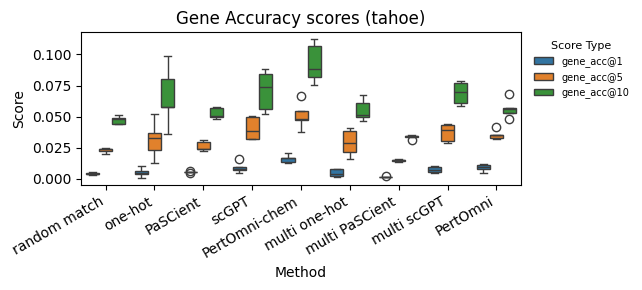

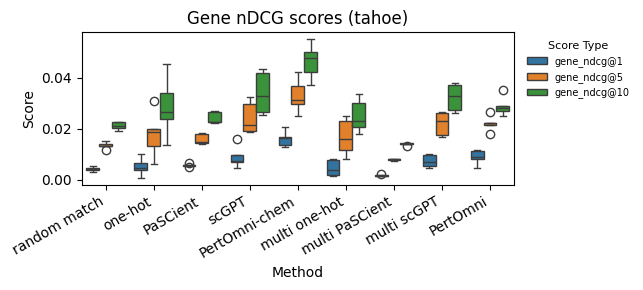

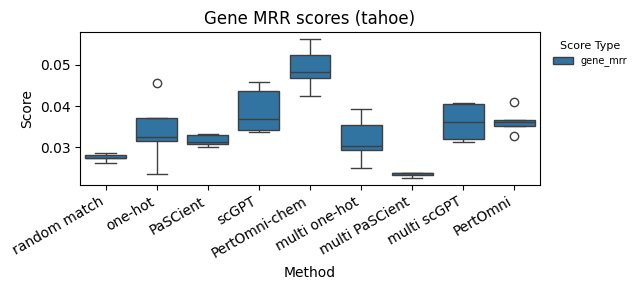

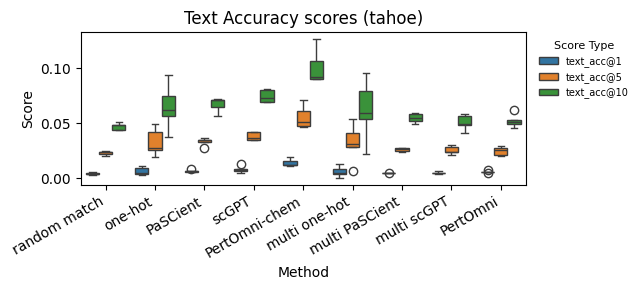

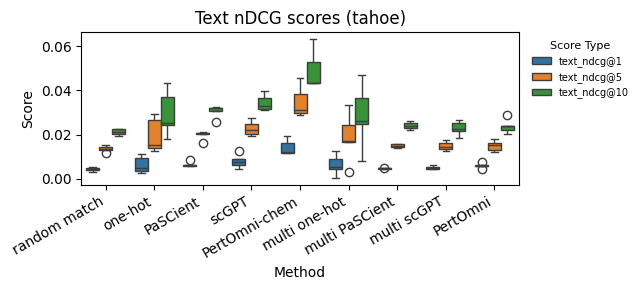

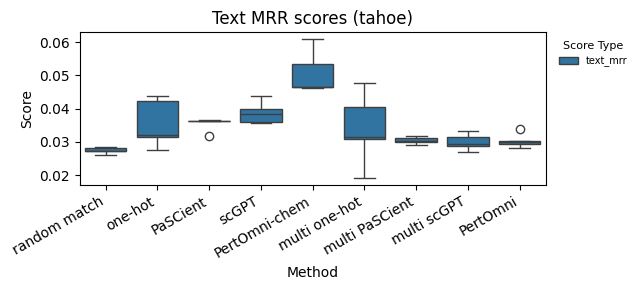

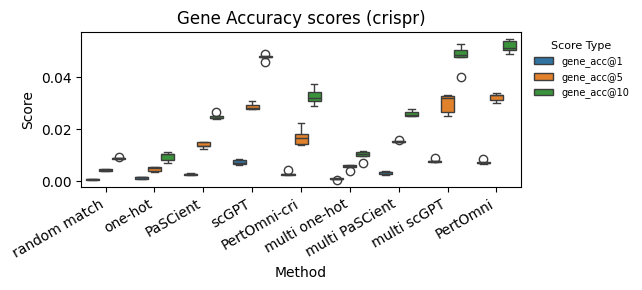

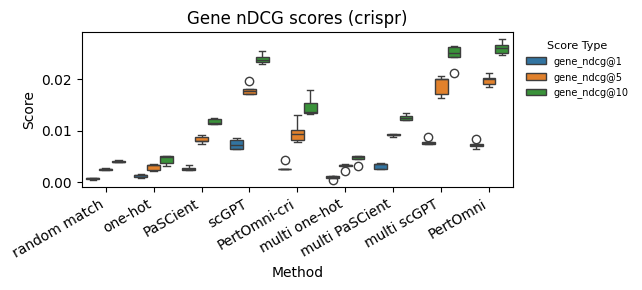

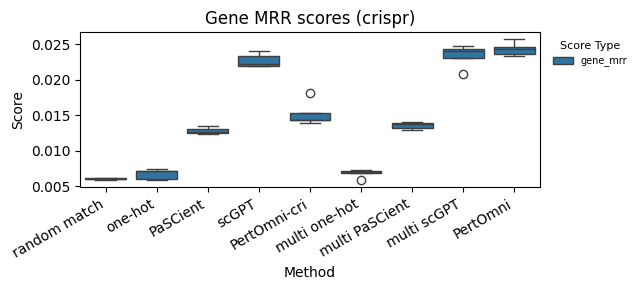

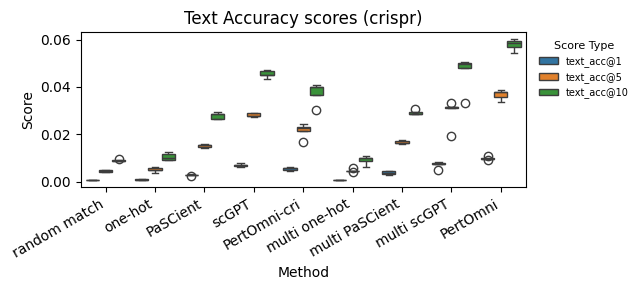

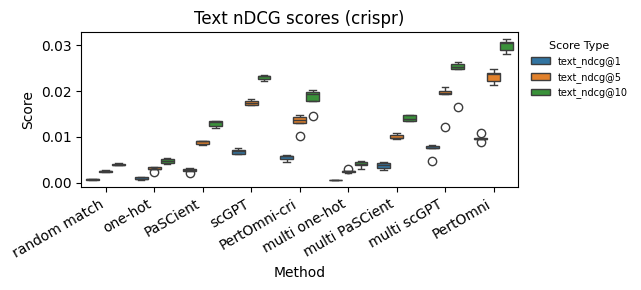

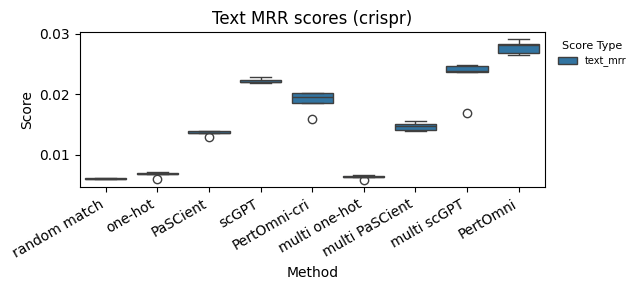

In [4]:
GROUPS = {"acc": ["acc@1", "acc@5", "acc@10"], "ndcg": ["ndcg@1", "ndcg@5", "ndcg@10"], "mrr": ["mrr"]}
TITLE = {"acc": "Accuracy", "ndcg": "nDCG", "mrr": "MRR"}

def plot_benchmark(ds, side, group):
    names = [f"{side}_{k}" for k in GROUPS[group]]
    d = scores[(scores["dataset"] == ds) & scores["metric"].isin(names)]
    fig, ax = plt.subplots(figsize=(6.5, 3))
    sns.boxplot(data=d, x="method", y="value", hue="metric", order=ORDER[ds], hue_order=names, ax=ax)
    ax.set_title(f"{side.capitalize()} {TITLE[group]} scores ({ds})")
    ax.set_xlabel("Method")
    ax.set_ylabel("Score")
    ax.tick_params(axis="x", rotation=30)
    for t in ax.get_xticklabels():
        t.set_ha("right")
    ax.legend(title="Score Type", fontsize=7, title_fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
    fig.tight_layout()
    fig.savefig(FIG / f"{ds}_{side}_{group}.pdf")
    plt.show()

for ds in ["tahoe", "crispr"]:
    for side in ["gene", "text"]:
        for group in GROUPS:
            plot_benchmark(ds, side, group)

## PertOmni vs each baseline

One-sided Wilcoxon signed-rank test over the 5 seeds (PertOmni > baseline) on MRR; with 5 paired values the smallest
possible p-value is 0.031.

In [5]:
from scipy.stats import wilcoxon
tests = []
for ds in ["tahoe", "crispr"]:
    for side in ["gene", "text"]:
        d = scores[(scores["dataset"] == ds) & (scores["metric"] == f"{side}_mrr")].pivot(index="seed", columns="method", values="value")
        for method in ORDER[ds]:
            if method != "PertOmni":
                tests.append(dict(dataset=ds, metric=f"{side}_mrr", baseline=method,
                                  mean_diff=(d["PertOmni"] - d[method]).mean(), p=wilcoxon(d["PertOmni"], d[method], alternative="greater").pvalue))
pd.DataFrame(tests).round(4)

,dataset,metric,baseline,mean_diff,p
0,tahoe,gene_mrr,random match,0.0089,0.0312
1,tahoe,gene_mrr,one-hot,0.0023,0.3125
2,tahoe,gene_mrr,PaSCient,0.0047,0.0625
3,tahoe,gene_mrr,scGPT,-0.0025,0.7812
4,tahoe,gene_mrr,PertOmni-chem,-0.0129,1.0000
5,tahoe,gene_mrr,multi one-hot,0.0045,0.0625
6,tahoe,gene_mrr,multi PaSCient,0.0129,0.0312
7,tahoe,gene_mrr,multi scGPT,0.0002,0.5000
8,tahoe,text_mrr,random match,0.0029,0.0312
9,tahoe,text_mrr,one-hot,-0.0051,0.9375
